<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; RETO 01 — Entrega Final (Hito 4)
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Camila González, Sebastián Haro, Matteo Valdivieso &bull; Periodo 2026-2
            </font></p>
        </td>
    </tr>
</table>

# 1. Título, objetivos y alcance (Hito 1)

## Ecuador y sus residuos: descubrimiento de perfiles de gestión municipal

### Pregunta esencial
> *¿Qué perfiles de gestión de residuos sólidos aparecen en los registros municipales del Ecuador (edición 2024) y cómo comunicar sus diferencias para orientar preguntas y propuestas de mejora técnica?*

### Objetivos y alcance del análisis
- **Contexto:** La gestión municipal de residuos sólidos combina barrido de vías, recolección, aprovechamiento de orgánicos, recuperación de inorgánicos y disposición final. Comparar a los 221 Gobiernos Autónomos Descentralizados (GAD) municipales exige distinguir entre diferencias de **escala operativa** y **prácticas de valorización**.
- **Objetivo general:** Identificar perfiles empíricos de gestión municipal mediante técnicas de aprendizaje no supervisado, evaluar su estabilidad y comunicar sus características en unidades originales para apoyar la discusión técnica.
- **Alcance y límites:** Este es un análisis **exploratorio** sobre los registros públicos de una sola edición (2024). No busca entrenar un clasificador supervisado, construir un ranking oficial de desempeño ni establecer relaciones causales o criterios directos de asignación presupuestaria.

### Breve descripción de las técnicas utilizadas
1. **K-Means:** Agrupamiento particional que minimiza la suma de distancias cuadradas dentro de cada grupo (inercia). Se evalúa para $k \in \{2, 3, 4, 5, 6\}$ y múltiples semillas aleatorias para verificar estabilidad.
2. **Agrupamiento jerárquico aglomerativo (enlace Ward + distancia euclidiana):** Construye una jerarquía de fusiones minimizando el incremento de varianza intragrupo en cada paso, lo que permite contrastar la estructura obtenida por K-Means mediante el dendrograma y el índice de Rand ajustado (ARI).
3. **Análisis de Componentes Principales (PCA):** Técnica de reducción de dimensionalidad empleada **exclusivamente para visualizar** los grupos en 2D e interpretar las direcciones principales de variación; todas las métricas de evaluación (silueta, inercia, ARI) se calculan sobre la matriz preparada original (5 dimensiones).

Resumen de la limpieza de datos: A partir de los 221 cantones originales del INEC (2024), se conservó el 100% de los registros y se depuraron las variables operativas clave: en cobertura de barrido (CSB) se asignó 0 a los cantones sin servicio de barrido, se corrigieron dos denominadores inconsistentes y se imputó la mediana válida (1.00) en cuatro cantones con servicio pero sin denominador registrado. Además, se homologaron todas las cantidades de flujo a toneladas/mes (CRR_t_mes, TROT_t_mes y RI_t_mes) para calcular tasas porcentuales válidas (Tasa_Org_pct y Tasa_Inorg_pct), descartando Pob (proyección urbana 2022) como denominador y dejando PORG_ref_pct solo como referencia por tener 51.13% de datos faltantes.

# 2. Fuente, auditoría y exploración de datos (Hito 1 — corregido)

### Registro de la base de datos
- **Fuente:** Instituto Nacional de Estadística y Censos (INEC) — *Estadística de Información Ambiental Económica en GAD Municipales: Gestión de Residuos Sólidos*.
- **Edición:** 2024 (uso exclusivo de esta edición).
- **Archivo fuente original del INEC:** `BDD_GIRS_2024_VF.csv` (221 cantones y 213 columnas, separador `;`, decimales `,`, codificación `cp1252`).
- **Base depurada utilizada (`BDD_GIRS_2024_LIMPIA.csv`):** Archivo de **221 registros y 15 columnas** (separador `,`, decimal `.`, codificación `utf-8-sig`, `CantonId` conservado como texto de 4 dígitos), alojado en el repositorio GitHub del equipo para asegurar carga directa y reproducibilidad tanto en Google Colab como en entornos locales.
- **Fecha de descarga del portal INEC:** 15 de octubre de 2026.

> **Trazabilidad de la depuración aplicada sobre `BDD_GIRS_2024_VF.csv`:**
> 1. **Identificadores y desagregación geográfica:** Se conservaron `'CantonId'` (texto de 4 dígitos con ceros iniciales), `'NombreCanton'`, `'Provin'` y `'Region'` (Sierra, Costa, Amazonía e Insular), reservándolos exclusivamente para interpretación.
> 2. **Descarte de denominadores inválidos:** Se excluyó `Pob` (población urbana proyectada a 2022) para evitar proporciones sesgadas sobre el servicio cantonal de 2024.
> 3. **Limpieza documentada de `CSB` (`CSB_limpia`):** De los 5 nulos y 4 valores $>1$ del archivo original, Paquisha (`1909`) y Gualaquiza (`1402`) se codificaron como `0.0` por no prestar servicio de barrido (`MR421 = 2`); Latacunga (`0501`) e Isabela (`2002`) se recalcularon con la suma real de vías susceptibles (`VB / (MR4221 + MR4222)`), obteniendo `0.9846` y `1.0000`; Biblián (`0302`) y Suscal (`0307`) se acotaron a `1.0` tras verificar superposición de barrido manual y mecánico; y los 4 cantones con servicio activo pero sin denominador registrado (`MR422 = 2`: Montecristi, Rocafuerte, Patate y Quero) se imputaron con la **mediana válida (`1.00`)**.
> 4. **Compatibilidad temporal de unidades:** Se verificó que `CRR` está en toneladas/mes (`MR453 * 30`), mientras que `TROT` estaba en escala anual (`MR4443 / 1000`) y `RI` en kg/mes (`MR4341_TOTAL_RES_REC / 12`). En `BDD_GIRS_2024_LIMPIA.csv` todas las cantidades se expresan en **toneladas/mes** (`CRR_t_mes`, `TROT_t_mes = TROT/12`, `RI_t_mes = RI/1000`), lo que permite calcular tasas porcentuales consistentes (`Tasa_Org_pct` y `Tasa_Inorg_pct`).

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

# Carga reproducible desde repositorio GitHub del equipo
URL_CSV = "https://raw.githubusercontent.com/Sebas086/aprendizaje-automatico-ActividadesVarias/refs/heads/main/BDD_GIRS_2024_LIMPIA.csv"
print(f"Cargando base desde: {URL_CSV}")

df = pd.read_csv(
    URL_CSV,
    sep=",",
    decimal=".",
    encoding="utf-8-sig",
    dtype={"CantonId": str, "Provin": str}
)
df["CantonId"] = df["CantonId"].str.zfill(4)
df["Provin"] = df["Provin"].str.zfill(2)

print(f"Dimensiones de la base cargada: {df.shape}")
print(f"Filas duplicadas: {df.duplicated().sum()}")
print(f"CantonId únicos: {df['CantonId'].nunique()}")
print(f"Columnas disponibles: {list(df.columns)}")
if df["CantonId"].nunique() == len(df):
    print("Verificación exitosa: cada fila representa un cantón único del Ecuador (221 GAD municipales).")

Cargando base desde: https://raw.githubusercontent.com/Sebas086/aprendizaje-automatico-ActividadesVarias/refs/heads/main/BDD_GIRS_2024_LIMPIA.csv
Dimensiones de la base cargada: (221, 15)
Filas duplicadas: 0
CantonId únicos: 221
Columnas disponibles: ['CantonId', 'NombreCanton', 'Provin', 'Region', 'VB_km', 'CSB_limpia', 'CRR_t_mes', 'TROT_t_mes', 'RI_t_mes', 'Tasa_Org_pct', 'Tasa_Inorg_pct', 'PORG_ref_pct', 'Perfil_Id', 'Perfil_Operativo', 'Silueta']
Verificación exitosa: cada fila representa un cantón único del Ecuador (221 GAD municipales).


### 2.1 Auditoría de disponibilidad en `BDD_GIRS_2024_LIMPIA.csv` (nulos, ceros y rangos)
Se inspeccionan las variables operativas depuradas (`VB_km`, `CSB_limpia`, `CRR_t_mes`, `TROT_t_mes`, `RI_t_mes`, `Tasa_Org_pct`, `Tasa_Inorg_pct`) junto con la variable de contraste `PORG_ref_pct` para verificar la integridad de la matriz y distinguir ausencia de actividad reportada (`0`) frente a datos faltantes (`NaN`).

In [8]:
num_cand = [
    "VB_km", "CSB_limpia", "CRR_t_mes", "TROT_t_mes",
    "RI_t_mes", "Tasa_Org_pct", "Tasa_Inorg_pct", "PORG_ref_pct"
]
resumen = []
for col in num_cand:
    s = pd.to_numeric(df[col], errors="coerce")
    resumen.append({
        "Variable": col,
        "Nulos": int(s.isna().sum()),
        "% Nulos": round(s.isna().mean() * 100, 2),
        "Ceros": int((s == 0).sum()),
        "% Ceros": round((s == 0).mean() * 100, 2),
        "Positivos": int((s > 0).sum()),
        "Mediana": round(float(s.median()), 2),
        "Máximo": round(float(s.max()), 2),
    })

df_disp = pd.DataFrame(resumen)
print("Resumen de disponibilidad y rangos en la base limpia:")
print(df_disp.to_string(index=False))

Resumen de disponibilidad y rangos en la base limpia:
      Variable  Nulos  % Nulos  Ceros  % Ceros  Positivos  Mediana    Máximo
         VB_km      0     0.00      2     0.90        219    18.11   4840.00
    CSB_limpia      0     0.00      2     0.90        219     1.00      1.00
     CRR_t_mes      0     0.00      0     0.00        221   369.30 121905.60
    TROT_t_mes      0     0.00    156    70.59         65     0.00    828.32
      RI_t_mes      0     0.00    135    61.09         86     0.00   1420.07
  Tasa_Org_pct      0     0.00    156    70.59         65     0.00     61.80
Tasa_Inorg_pct      0     0.00    139    62.90         82     0.00     36.61
  PORG_ref_pct    113    51.13      2     0.90        106    58.95     86.43


**Observaciones de la auditoría de disponibilidad:**
- `PORG_ref_pct` (fracción orgánica de la caracterización física) presenta **113 nulos (51.13%)**, es decir, solo 108 cantones realizaron estudios de caracterización; por ello se conserva únicamente como referencia contextual y **no se incluye** en las distancias de agrupamiento.
- `TROT_t_mes` (156 ceros, 70.59%) y `RI_t_mes` (135 ceros, 61.09%) tienen **0% de nulos**: los ceros reflejan **ausencia de actividad reportada** de tratamiento de orgánicos o recuperación de inorgánicos, información esencial para diferenciar perfiles de gestión.
- Gracias a la homologación previa a toneladas/mes, `Tasa_Org_pct` (máximo `61.80%` en Pedro Vicente Maldonado) y `Tasa_Inorg_pct` (máximo `36.61%` en Macará) se mantienen estrictamente dentro del rango físico $[0\%, 100\%]$.

### 2.2 Distribuciones exploratorias (escala original vs. transformada)

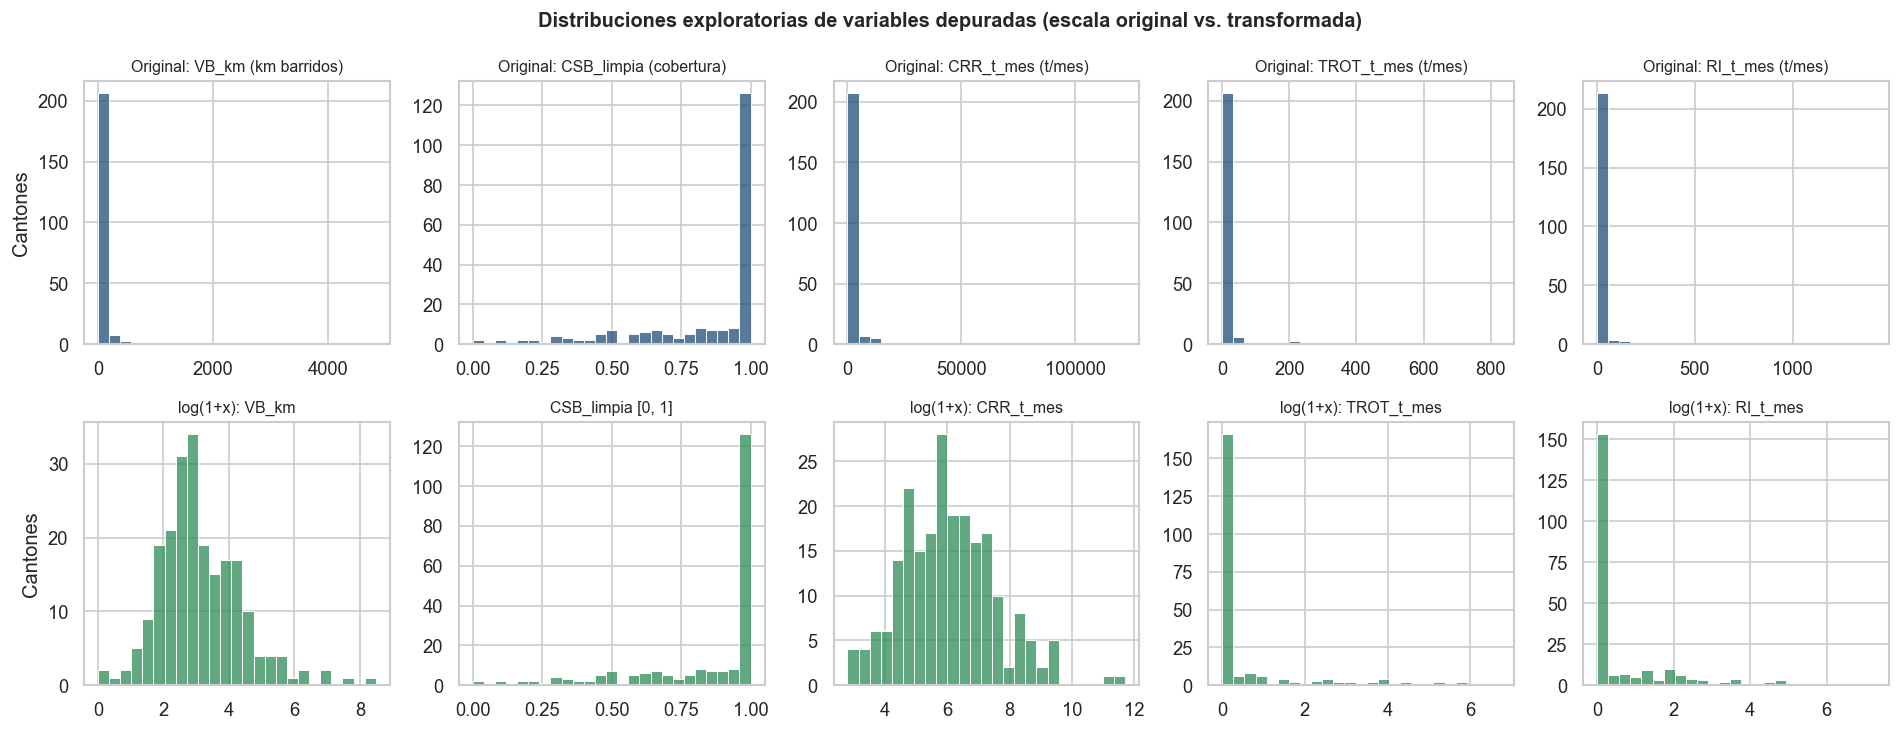

In [9]:
vb = df["VB_km"]
csb_imp = df["CSB_limpia"]
crr = df["CRR_t_mes"]
trot_mes = df["TROT_t_mes"]
ri_ton = df["RI_t_mes"]
tasa_org_pct = df["Tasa_Org_pct"]
tasa_inorg_pct = df["Tasa_Inorg_pct"]

fig, axes = plt.subplots(2, 5, figsize=(16, 6.2))
plot_vars = [
    ("VB_km (km barridos)", vb, np.log1p(vb)),
    ("CSB_limpia (cobertura)", csb_imp, csb_imp),
    ("CRR_t_mes (t/mes)", crr, np.log1p(crr)),
    ("TROT_t_mes (t/mes)", trot_mes, np.log1p(trot_mes)),
    ("RI_t_mes (t/mes)", ri_ton, np.log1p(ri_ton)),
]

for j, (title, raw_s, tr_s) in enumerate(plot_vars):
    sns.histplot(raw_s, bins=25, ax=axes[0, j], color="#1f4e79", edgecolor="white")
    axes[0, j].set_title(f"Original: {title}", fontsize=9.5)
    axes[0, j].set_xlabel("")
    axes[0, j].set_ylabel("Cantones" if j == 0 else "")

    lbl_tr = "CSB_limpia [0, 1]" if j == 1 else f"log(1+x): {title.split(' ')[0]}"
    sns.histplot(tr_s, bins=25, ax=axes[1, j], color="#2e8b57", edgecolor="white")
    axes[1, j].set_title(lbl_tr, fontsize=9.5)
    axes[1, j].set_xlabel("")
    axes[1, j].set_ylabel("Cantones" if j == 0 else "")

fig.suptitle("Distribuciones exploratorias de variables depuradas (escala original vs. transformada)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Diccionario de características elegidas (comparación de dos enfoques)
Para responder a la pregunta guía sobre **qué cambia al usar cantidades absolutas frente a indicadores relativos**, se evalúan explícitamente **dos matrices de 5 características** (ambas dentro del rango de 4 a 8 variables, sin `Pob` y sin variables redundantes):

| Variable / Indicador | Columna en `BDD_GIRS_2024_LIMPIA.csv` | Definición sustantiva | Unidad verificada | Transformación | Enfoque A (Absolutas) | Enfoque B (Mixtas / Relativas) |
| :--- | :--- | :--- | :--- | :--- | :---: | :---: |
| **Vías barridas** | `VB_km` | Longitud de vías urbanas y rurales barridas (manual + mecánico) | km | $\log(1 + x)$ + Z-score | Sí | Sí |
| **Cobertura de barrido** | `CSB_limpia` | Fracción depurada de vías susceptibles cubiertas por el servicio | Proporción (0–1) | Z-score | Sí | Sí |
| **Residuos recolectados** | `CRR_t_mes` | Volumen mensual de residuos sólidos recolectados | toneladas/mes | $\log(1 + x)$ + Z-score | Sí | Sí |
| **Orgánicos tratados (abs.)** | `TROT_t_mes` | Residuos orgánicos aprovechados convertidos a escala mensual | toneladas/mes | $\log(1 + x)$ + Z-score | Sí | — |
| **Inorgánicos recuperados (abs.)** | `RI_t_mes` | Residuos inorgánicos recuperados convertidos a toneladas/mes | toneladas/mes | $\log(1 + x)$ + Z-score | Sí | — |
| **Tasa de valorización orgánica** | `Tasa_Org_pct` | Porcentaje mensual de residuos orgánicos tratados respecto a `CRR_t_mes` | % (0–61.8%) | $\log(1 + \%)$ + Z-score | — | Sí |
| **Tasa de recuperación inorgánica** | `Tasa_Inorg_pct` | Porcentaje mensual de inorgánicos recuperados respecto a `CRR_t_mes` | % (0–36.6%) | $\log(1 + \%)$ + Z-score | — | Sí |

# 3. Preparación de la matriz (Hito 2)

### Decisiones de preprocesamiento justificadas
1. **Integridad de variables depuradas:** Se trabaja sobre las columnas depuradas (`VB_km`, `CSB_limpia`, `CRR_t_mes`, `TROT_t_mes`, `RI_t_mes`, `Tasa_Org_pct`, `Tasa_Inorg_pct`), sin valores faltantes ni inconsistencias de escala.
2. **Atípicos y conservación de registros:** Se conservan los **221 cantones (100%)**. No se eliminan metrópolis como Quito (`1701`) o Guayaquil (`0901`) ni cantones con alto reciclaje solo para inflar la silueta; en su lugar, la transformación $\log(1 + x)$ comprime las colas extremas sin alterar el orden relativo.
3. **Escalado uniforme:** Todas las características se estandarizan con `StandardScaler` (media 0, desviación estándar 1) para que ninguna variable domine las distancias euclidianas por su magnitud numérica. Los identificadores (`CantonId`, `NombreCanton`), categorías (`Provin`, `Region`) y columnas de referencia (`PORG_ref_pct`) se reservan exclusivamente para la interpretación.

In [10]:
# 1. Construcción de matrices antes del escalado
df_A = pd.DataFrame({
    "log_VB": np.log1p(vb),
    "CSB": csb_imp,
    "log_CRR": np.log1p(crr),
    "log_TROT_mes": np.log1p(trot_mes),
    "log_RI_ton": np.log1p(ri_ton),
})

df_B = pd.DataFrame({
    "log_VB": np.log1p(vb),
    "CSB": csb_imp,
    "log_CRR": np.log1p(crr),
    "log_tasa_org": np.log1p(tasa_org_pct),
    "log_tasa_inorg": np.log1p(tasa_inorg_pct),
})

# 2. Estandarización (media 0, desviación 1)
scaler_A = StandardScaler()
scaler_B = StandardScaler()
X_A = scaler_A.fit_transform(df_A)
X_B = scaler_B.fit_transform(df_B)

print(f"Registros conservados: {len(df_B)} de {len(df)} cantones (100% — no se eliminan atípicos).")
print(f"Nulos restantes en Matriz A: {df_A.isna().sum().sum()} | en Matriz B: {df_B.isna().sum().sum()}")
print(f"Dimensiones de ambas matrices escaladas: {X_B.shape}")

Registros conservados: 221 de 221 cantones (100% — no se eliminan atípicos).
Nulos restantes en Matriz A: 0 | en Matriz B: 0
Dimensiones de ambas matrices escaladas: (221, 5)


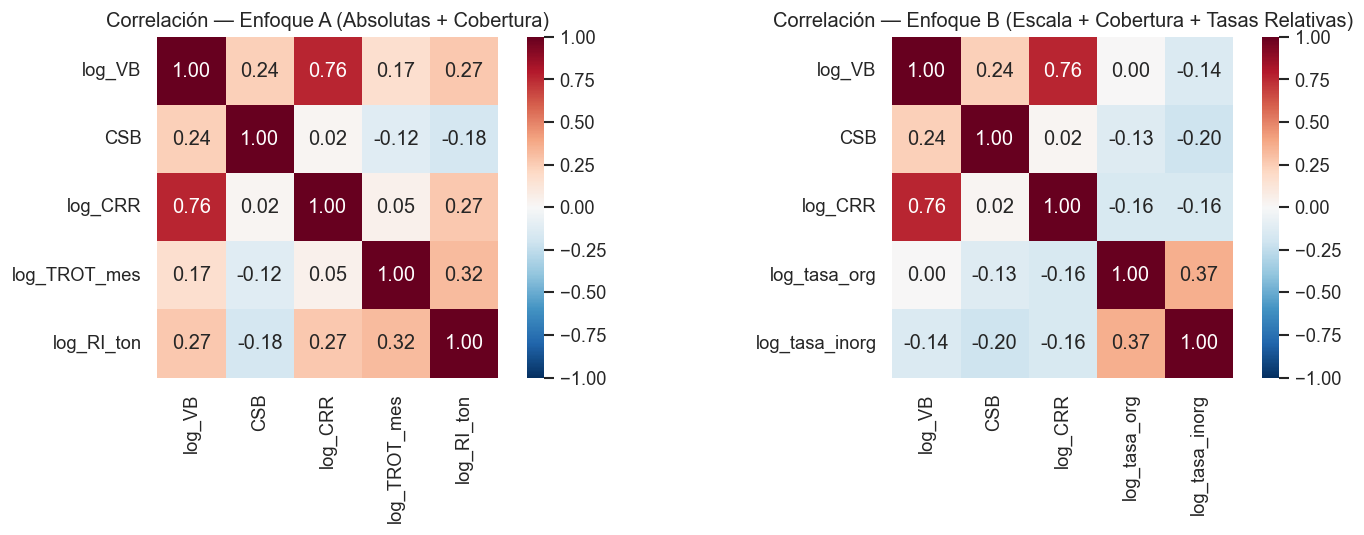

In [11]:
# Inspección de correlaciones para verificar ausencia de redundancia excesiva
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
sns.heatmap(df_A.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title("Correlación — Enfoque A (Absolutas + Cobertura)")

sns.heatmap(df_B.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1], square=True)
axes[1].set_title("Correlación — Enfoque B (Escala + Cobertura + Tasas Relativas)")
plt.tight_layout()
plt.show()

**Lectura de las correlaciones:**
- En ambos enfoques `log_VB` y `log_CRR` se correlacionan positivamente ($r \approx 0.77$), ya que los cantones más grandes recolectan más residuos y barren más kilómetros de vías, pero `CSB` (cobertura relativa) aporta información independiente.
- En el **Enfoque A**, los volúmenes absolutos de valorización (`log_TROT_mes`, `log_RI_ton`) presentan correlación positiva con la escala (`log_CRR`), lo que tiende a mezclar tamaño con gestión. En el **Enfoque B**, las tasas relativas (`log_tasa_org`, `log_tasa_inorg`) se desacoplan de la escala (`r` cercano a cero o ligeramente negativo con `log_CRR`), permitiendo distinguir **esfuerzo relativo de valorización** independientemente del tamaño del cantón.

# 4. Agrupamiento comparativo: K-Means vs. Jerárquico Ward (Hito 2 y Hito 3)

### Configuración de los algoritmos
- **K-Means:** inicialización `k-means++`, `n_init=20`, `random_state=42` (más análisis de sensibilidad con 9 semillas).
- **Agrupamiento jerárquico:** enlace **Ward** con **distancia euclidiana**. Se elige Ward porque minimiza el incremento de varianza intragrupo en cada fusión —un criterio geométricamente coherente con la función objetivo de K-Means— y tiende a formar grupos más compactos que enlace simple o promedio en presencia de colas asimétricas.
- **Rango evaluado:** $k \in \{2, 3, 4, 5, 6\}$ sobre las mismas matrices estandarizadas (Enfoque A y Enfoque B).

In [12]:
filas = []
for nombre, X_mat in [("Enfoque A (Absolutas)", X_A), ("Enfoque B (Mixtas/Relativas)", X_B)]:
    for k in range(2, 7):
        km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_mat)
        hc = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit(X_mat)

        sil_km = silhouette_score(X_mat, km.labels_)
        sil_hc = silhouette_score(X_mat, hc.labels_)
        sz_km = sorted(np.bincount(km.labels_).tolist(), reverse=True)
        sz_hc = sorted(np.bincount(hc.labels_).tolist(), reverse=True)
        ari_kh = adjusted_rand_score(km.labels_, hc.labels_)

        filas.append({
            "Enfoque": nombre,
            "k": k,
            "Silueta KM": round(sil_km, 3),
            "Inercia KM": round(km.inertia_, 1),
            "Tamaños KM": str(sz_km),
            "Silueta Ward": round(sil_hc, 3),
            "Tamaños Ward": str(sz_hc),
            "ARI (KM vs Ward)": round(ari_kh, 3),
        })

df_comp = pd.DataFrame(filas)
print(df_comp.to_string(index=False))

                     Enfoque  k  Silueta KM  Inercia KM               Tamaños KM  Silueta Ward             Tamaños Ward  ARI (KM vs Ward)
       Enfoque A (Absolutas)  2       0.322       833.0                [154, 67]         0.372                [193, 28]             0.160
       Enfoque A (Absolutas)  3       0.237       672.1            [116, 77, 28]         0.234            [132, 61, 28]             0.287
       Enfoque A (Absolutas)  4       0.314       532.9        [114, 45, 43, 19]         0.236         [91, 61, 41, 28]             0.532
       Enfoque A (Absolutas)  5       0.305       458.7    [101, 51, 39, 19, 11]         0.246     [91, 41, 32, 29, 28]             0.534
       Enfoque A (Absolutas)  6       0.265       413.0 [83, 42, 32, 31, 18, 15]         0.262  [91, 41, 29, 29, 28, 3]             0.396
Enfoque B (Mixtas/Relativas)  2       0.371       839.3                [169, 52]         0.378                [178, 43]             0.752
Enfoque B (Mixtas/Relativas)  3   

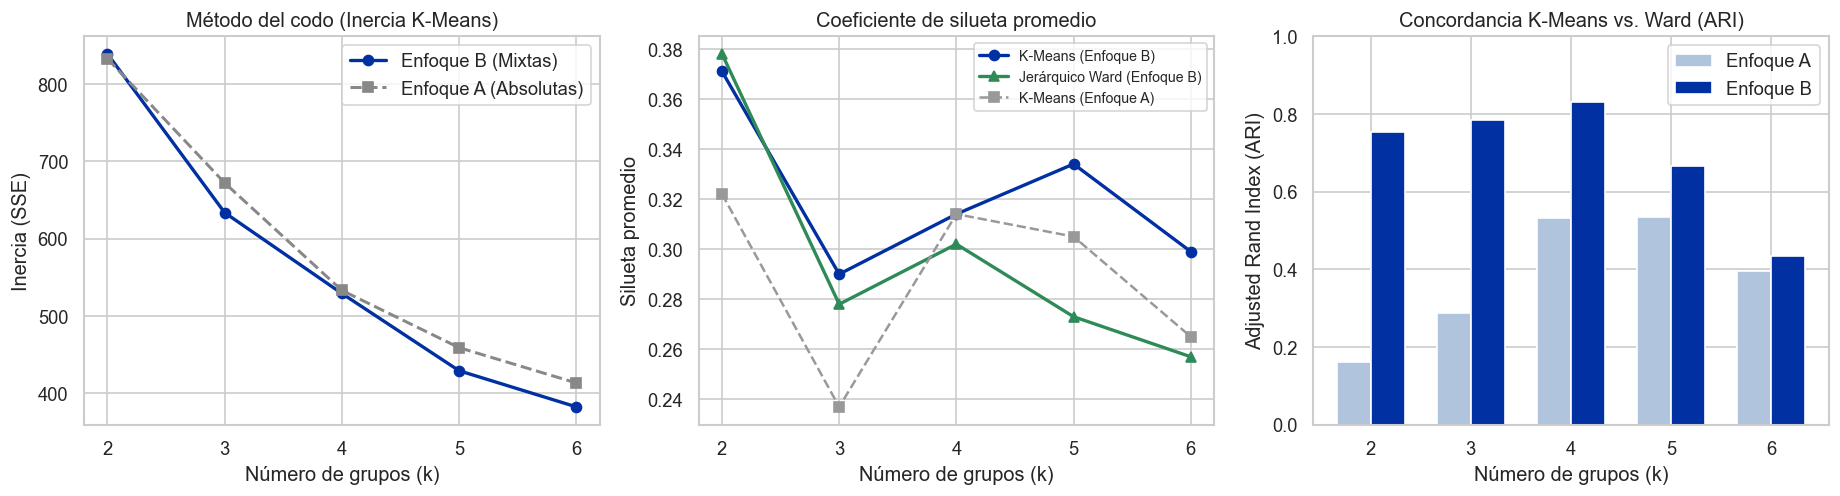

In [13]:
# Visualización comparativa: Inercia, Silueta y Concordancia (ARI)
ks = list(range(2, 7))
sub_A = df_comp[df_comp["Enfoque"].str.startswith("Enfoque A")]
sub_B = df_comp[df_comp["Enfoque"].str.startswith("Enfoque B")]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))

axes[0].plot(ks, sub_B["Inercia KM"], marker="o", lw=2, color="#0030A1", label="Enfoque B (Mixtas)")
axes[0].plot(ks, sub_A["Inercia KM"], marker="s", lw=1.8, ls="--", color="#888888", label="Enfoque A (Absolutas)")
axes[0].set_title("Método del codo (Inercia K-Means)")
axes[0].set_xlabel("Número de grupos (k)")
axes[0].set_ylabel("Inercia (SSE)")
axes[0].set_xticks(ks)
axes[0].legend()

axes[1].plot(ks, sub_B["Silueta KM"], marker="o", lw=2, color="#0030A1", label="K-Means (Enfoque B)")
axes[1].plot(ks, sub_B["Silueta Ward"], marker="^", lw=2, color="#2e8b57", label="Jerárquico Ward (Enfoque B)")
axes[1].plot(ks, sub_A["Silueta KM"], marker="s", lw=1.5, ls="--", color="#999999", label="K-Means (Enfoque A)")
axes[1].set_title("Coeficiente de silueta promedio")
axes[1].set_xlabel("Número de grupos (k)")
axes[1].set_ylabel("Silueta promedio")
axes[1].set_xticks(ks)
axes[1].legend(fontsize=8.5)

axes[2].bar([k - 0.17 for k in ks], sub_A["ARI (KM vs Ward)"], width=0.34, color="#b0c4de", label="Enfoque A")
axes[2].bar([k + 0.17 for k in ks], sub_B["ARI (KM vs Ward)"], width=0.34, color="#0030A1", label="Enfoque B")
axes[2].set_title("Concordancia K-Means vs. Ward (ARI)")
axes[2].set_xlabel("Número de grupos (k)")
axes[2].set_ylabel("Adjusted Rand Index (ARI)")
axes[2].set_xticks(ks)
axes[2].set_ylim(0, 1.0)
axes[2].legend()

plt.tight_layout()
plt.show()

### 4.1 Dendrograma del agrupamiento jerárquico (Enfoque B)
El Enfoque B logra una estructura notablemente más consistente entre K-Means y Ward (`ARI` entre `0.665` y `0.831` para $k \in \{2,3,4,5\}$, frente a `0.160–0.534` en el Enfoque A). Visualizamos su dendrograma con enlace Ward:

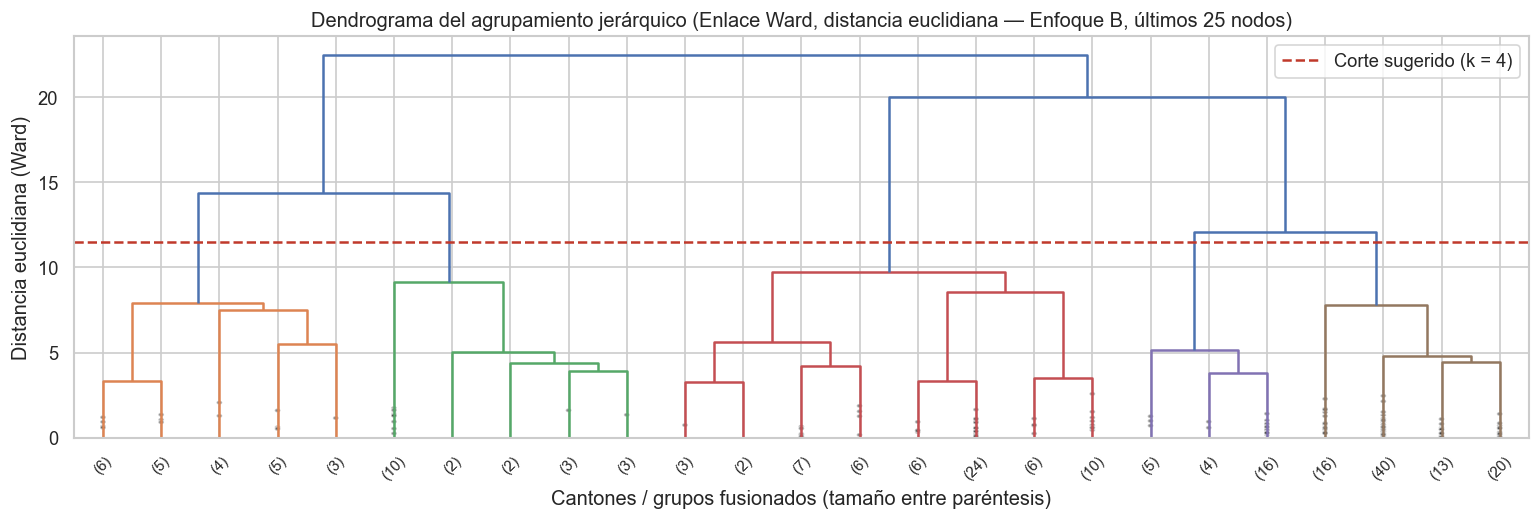

In [14]:
Z_B = linkage(X_B, method="ward", metric="euclidean")

fig, ax = plt.subplots(figsize=(13, 4.5))
dendrogram(
    Z_B,
    truncate_mode="lastp",
    p=25,
    leaf_rotation=45,
    leaf_font_size=9,
    show_contracted=True,
    color_threshold=11.5,
    ax=ax
)
ax.axhline(y=11.5, color="#c0392b", linestyle="--", lw=1.5, label="Corte sugerido (k = 4)")
ax.set_title("Dendrograma del agrupamiento jerárquico (Enlace Ward, distancia euclidiana — Enfoque B, últimos 25 nodos)")
ax.set_xlabel("Cantones / grupos fusionados (tamaño entre paréntesis)")
ax.set_ylabel("Distancia euclidiana (Ward)")
ax.legend()
plt.tight_layout()
plt.show()

### 4.2 Análisis de estabilidad de K-Means frente a múltiples inicializaciones (semillas)
Evaluamos 9 semillas distintas (`[0, 7, 13, 21, 42, 99, 123, 2024, 2026]`) comparando una sola inicialización (`n_init=1`) frente a 20 reinicios (`n_init=20`) para $k \in \{3, 4, 5\}$ en el Enfoque B:

In [15]:
seeds = [0, 7, 13, 21, 42, 99, 123, 2024, 2026]
filas_stab = []

for k in [3, 4, 5]:
    ref = KMeans(n_clusters=k, n_init=30, random_state=42).fit(X_B).labels_
    aris_1 = [
        adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=1, random_state=s).fit(X_B).labels_)
        for s in seeds
    ]
    aris_20 = [
        adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=20, random_state=s).fit(X_B).labels_)
        for s in seeds
    ]
    filas_stab.append({
        "k": k,
        "ARI mín (n_init=1)": round(min(aris_1), 3),
        "ARI prom (n_init=1)": round(float(np.mean(aris_1)), 3),
        "ARI mín (n_init=20)": round(min(aris_20), 3),
        "ARI prom (n_init=20)": round(float(np.mean(aris_20)), 3),
    })

print(f"Semillas evaluadas: {seeds}")
print(pd.DataFrame(filas_stab).to_string(index=False))

Semillas evaluadas: [0, 7, 13, 21, 42, 99, 123, 2024, 2026]
 k  ARI mín (n_init=1)  ARI prom (n_init=1)  ARI mín (n_init=20)  ARI prom (n_init=20)
 3               0.482                0.856                  1.0                   1.0
 4               0.430                0.510                  1.0                   1.0
 5               0.983                0.989                  1.0                   1.0


### 4.3 Justificación de la solución seleccionada: Enfoque B, K-Means con $k = 4$
No se elige $k = 2$ (aunque tiene la silueta más alta, `0.371`) porque colapsa a los 221 cantones en una dicotomía demasiado gruesa (169 vs. 52) que oculta la diferencia entre valorización orgánica, reciclaje inorgánico y escala urbana.
Se selecciona **Enfoque B con K-Means ($k = 4$, `n_init=20`)** por cuatro criterios convergentes:
1. **Máxima concordancia entre algoritmos:** alcanza el `ARI(KM, Ward)` más alto de toda la tabla (**0.831**), con tamaños casi idénticos (`[117, 65, 22, 17]` en K-Means vs. `[114, 64, 23, 20]` en Ward).
2. **Alta reproducibilidad:** con `n_init=20`, la partición es completamente estable en las 9 semillas (`ARI = 1.000`). A la vez, el experimento con `n_init=1` (`ARI` mínimo `0.430`) demuestra que el espacio 5D tiene óptimos locales y justifica exigir múltiples reinicios.
3. **Claridad sustantiva sin microgrupos:** separa cuatro perfiles bien diferenciados y con tamaños útiles para política pública (17 a 117 cantones), sin fragmentar en grupos de 3 municipios como ocurre en $k = 6$ del Enfoque A.
4. **Matiz respecto a $k = 5$:** con $k = 5$ (silueta `0.334`, `ARI(KM, Ward) = 0.665`), el grupo mayoritario se subdivide para aislar un 5.º perfil de **34 cantones con baja cobertura de barrido (`CSB` mediana = 0.50)**, manteniendo intactos los perfiles de valorización orgánica (17) e inorgánica (21). Este matiz se conserva como insumo útil en la discusión de estabilidad.

# 5. Visualización con PCA (Hito 2 y Hito 3)

Aplicamos Análisis de Componentes Principales (PCA) sobre la matriz preparada de 5 dimensiones (`X_B`) para proyectar los 4 grupos en un plano 2D e interpretar qué variables impulsan cada eje. **Importante:** PCA se utiliza únicamente para visualización; las métricas de silueta, inercia y ARI reportadas en la sección 4 se calcularon en el espacio completo de 5 variables.

In [16]:
# Ajuste final K-Means k=4 en Enfoque B
km_final = KMeans(n_clusters=4, n_init=30, random_state=42).fit(X_B)
raw_lbl = km_final.labels_

# Reetiquetado determinístico de los 4 perfiles (sin orden jerárquico de calidad)
tmp_map = pd.DataFrame({"raw": raw_lbl, "crr": crr, "t_org": tasa_org_pct, "t_inorg": tasa_inorg_pct})
g_stats = tmp_map.groupby("raw").agg(crr_m=("crr", "median"), org_m=("t_org", "median"), inorg_m=("t_inorg", "median"))
c_org = int(g_stats["org_m"].idxmax())
c_inorg = int(g_stats.drop(index=[c_org])["inorg_m"].idxmax())
rem = g_stats.drop(index=[c_org, c_inorg])
c_grande = int(rem["crr_m"].idxmax())
c_basica = int(rem["crr_m"].idxmin())

label_order = {c_basica: 0, c_grande: 1, c_inorg: 2, c_org: 3}
short_names = {0: "P1: Básica", 1: "P2: Gran escala", 2: "P3: Inorgánicos", 3: "P4: Orgánicos"}
km4_lbl = np.array([label_order[x] for x in raw_lbl])

# Verificación de concordancia exacta con Perfil_Id guardado en BDD_GIRS_2024_LIMPIA.csv
ari_guardado = adjusted_rand_score(df["Perfil_Id"] - 1, km4_lbl)
print(f"Concordancia (ARI) respecto a Perfil_Id en la base limpia: {ari_guardado:.3f}")

# PCA sobre X_B
pca = PCA()
scores = pca.fit_transform(X_B)
var_ratio = pca.explained_variance_ratio_
Vt = pca.components_.copy()

# Orientación consistente de ejes para facilitar lectura visual
if Vt[0, 2] < 0:
    Vt[0], scores[:, 0] = -Vt[0], -scores[:, 0]
if Vt[1, 3] < 0:
    Vt[1], scores[:, 1] = -Vt[1], -scores[:, 1]

df_pca_var = pd.DataFrame({
    "Componente": [f"PC{i+1}" for i in range(len(var_ratio))],
    "Varianza explicada (%)": np.round(var_ratio * 100, 2),
    "Varianza acumulada (%)": np.round(np.cumsum(var_ratio) * 100, 2),
})
df_loadings = pd.DataFrame(Vt[:2].T, index=df_B.columns, columns=["PC1 (Escala operativa)", "PC2 (Valorización)"]).round(3)

print("\n=== Varianza explicada por componente (PCA sobre matriz 5D estandarizada) ===")
print(df_pca_var.to_string(index=False))
print("\n=== Cargas (contribuciones de variables a PC1 y PC2) ===")
print(df_loadings.to_string())

Concordancia (ARI) respecto a Perfil_Id en la base limpia: 1.000

=== Varianza explicada por componente (PCA sobre matriz 5D estandarizada) ===
Componente  Varianza explicada (%)  Varianza acumulada (%)
       PC1                   38.95                   38.95
       PC2                   26.09                   65.04
       PC3                   18.73                   83.78
       PC4                   12.52                   96.29
       PC5                    3.71                  100.00

=== Cargas (contribuciones de variables a PC1 y PC2) ===
                PC1 (Escala operativa)  PC2 (Valorización)
log_VB                           0.600               0.390
CSB                              0.280              -0.290
log_CRR                          0.596               0.346
log_tasa_org                    -0.278               0.593
log_tasa_inorg                  -0.360               0.541


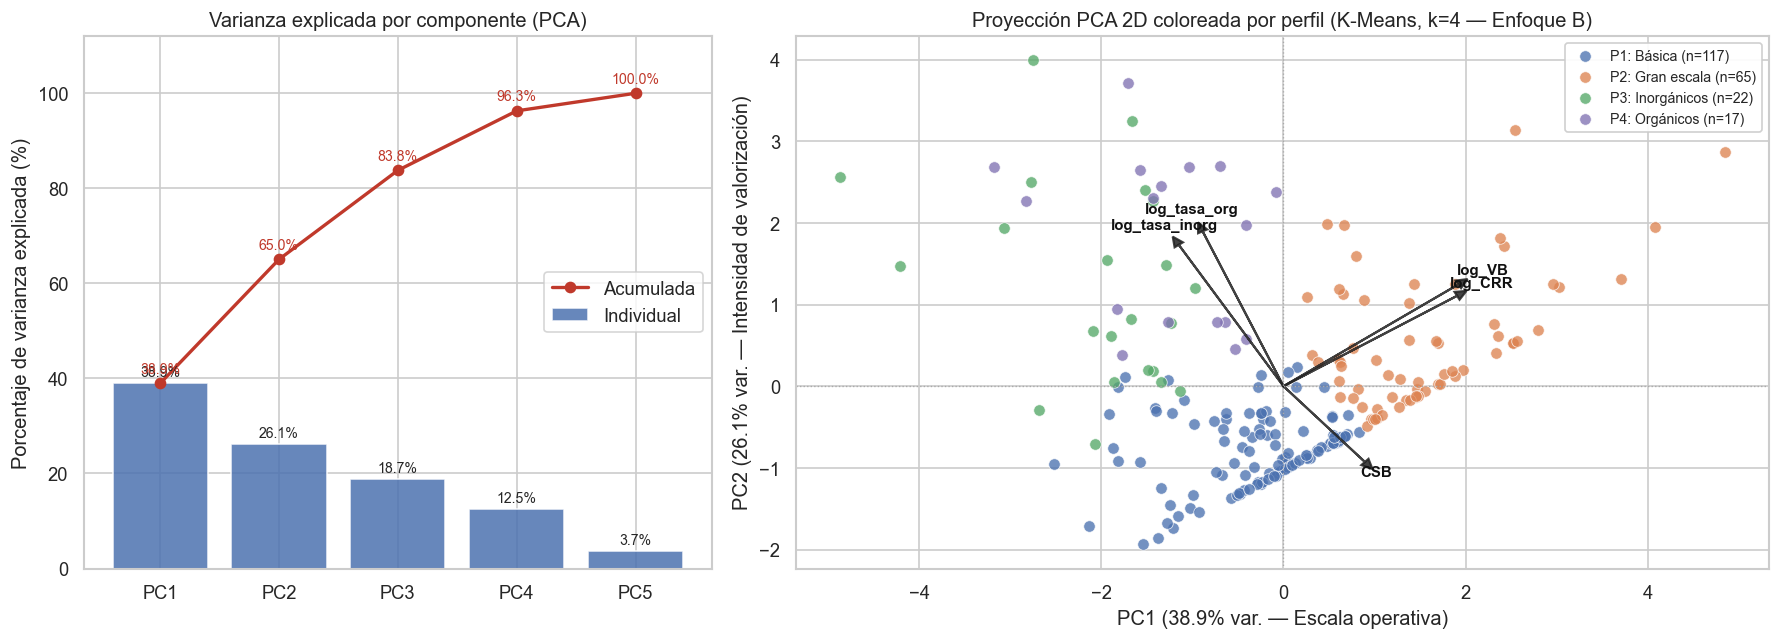

In [17]:
# Scree plot + Biplot PCA 2D coloreado por perfil
palette = {0: "#4c72b0", 1: "#dd8452", 2: "#55a868", 3: "#8172b3"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.55]})

# Varianza explicada
x_pc = np.arange(1, 6)
axes[0].bar(x_pc, var_ratio * 100, color="#4c72b0", alpha=0.85, label="Individual")
axes[0].plot(x_pc, np.cumsum(var_ratio) * 100, color="#c0392b", marker="o", lw=2, label="Acumulada")
for i, (vi, vc) in enumerate(zip(var_ratio * 100, np.cumsum(var_ratio) * 100)):
    axes[0].text(i + 1, vi + 1.5, f"{vi:.1f}%", ha="center", fontsize=8.5)
    axes[0].text(i + 1, vc + 2.2, f"{vc:.1f}%", ha="center", fontsize=8.5, color="#c0392b")
axes[0].set_ylim(0, 112)
axes[0].set_xticks(x_pc)
axes[0].set_xticklabels([f"PC{i}" for i in x_pc])
axes[0].set_ylabel("Porcentaje de varianza explicada (%)")
axes[0].set_title("Varianza explicada por componente (PCA)")
axes[0].legend(loc="center right")

# Biplot 2D
for c in range(4):
    m = km4_lbl == c
    axes[1].scatter(
        scores[m, 0], scores[m, 1],
        c=palette[c], label=f"{short_names[c]} (n={m.sum()})",
        alpha=0.78, s=48, edgecolors="white", lw=0.5
    )

scale_arrow = 3.2
for idx_v, var_name in enumerate(df_B.columns):
    dx, dy = Vt[0, idx_v] * scale_arrow, Vt[1, idx_v] * scale_arrow
    axes[1].arrow(0, 0, dx, dy, color="#222222", alpha=0.85, head_width=0.11, head_length=0.12, lw=1.3)
    axes[1].text(dx * 1.14, dy * 1.14, var_name, color="#111111", fontsize=9, fontweight="bold", ha="center", va="center")

axes[1].axhline(0, color="#aaaaaa", lw=0.8, ls=":")
axes[1].axvline(0, color="#aaaaaa", lw=0.8, ls=":")
axes[1].set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}% var. — Escala operativa)")
axes[1].set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}% var. — Intensidad de valorización)")
axes[1].set_title("Proyección PCA 2D coloreada por perfil (K-Means, k=4 — Enfoque B)")
axes[1].legend(loc="upper right", fontsize=8.5, framealpha=0.92)
plt.tight_layout()
plt.show()

**Interpretación de las componentes principales:**
- Las dos primeras componentes explican **65.04% de la varianza total** (`PC1 = 38.94%`, `PC2 = 26.10%`); el 34.96% restante reside en `PC3–PC5` (principalmente variación específica de `CSB` y diferenciación entre orgánicos vs. inorgánicos), lo que explica cierto solapamiento visual en 2D entre `P3` y `P4` que sí se separa en 5D.
- **PC1 (Eje de escala operativa):** dominado positivamente por `log_VB` (`+0.600`) y `log_CRR` (`+0.596`), con aporte moderado de `CSB` (`+0.280`). Separa los municipios urbanos de gran volumen (derecha) de los cantones pequeños y medianos (izquierda).
- **PC2 (Eje de intensidad de valorización):** dominado positivamente por `log_tasa_org` (`+0.593`) y `log_tasa_inorg` (`+0.541`), y moderadamente por `log_VB`/`log_CRR` (`+0.390`/`+0.346`). Eleva hacia la parte superior a los cantones que aprovechan una fracción importante de sus residuos.

# 6. Interpretación de perfiles, casos frontera y estabilidad (Hito 3)

Caracterizamos cada uno de los 4 perfiles en **unidades originales** (usando medianas por la fuerte asimetría de los volúmenes, junto con porcentajes de cantones que reportan actividad) e identificamos tanto ejemplos representativos como cantones con silueta negativa poco representados por su perfil.

In [18]:
sil4 = silhouette_samples(X_B, km4_lbl)

df_res = pd.DataFrame({
    "CantonId": df["CantonId"],
    "NombreCantón": df["NombreCanton"],
    "Region": df["Region"],
    "Perfil": [short_names[c] for c in km4_lbl],
    "cluster": km4_lbl,
    "VB": vb,
    "CSB": csb_imp,
    "CRR": crr,
    "TROT_mes": trot_mes,
    "RI_ton": ri_ton,
    "tasa_org_pct": tasa_org_pct,
    "tasa_inorg_pct": tasa_inorg_pct,
    "silueta": sil4,
})

prof_tbl = df_res.groupby("cluster").agg(
    Cantones=("CantonId", "count"),
    Pct_total=("CantonId", lambda s: round(len(s) / len(df_res) * 100, 1)),
    VB_med_km=("VB", "median"),
    CSB_med=("CSB", "median"),
    CRR_med_tmes=("CRR", "median"),
    TROT_med_tmes=("TROT_mes", "median"),
    RI_med_tmes=("RI_ton", "median"),
    Tasa_org_med_pct=("tasa_org_pct", "median"),
    Tasa_inorg_med_pct=("tasa_inorg_pct", "median"),
    Pct_trata_org=("TROT_mes", lambda s: (s > 0).mean() * 100),
    Pct_recup_inorg=("RI_ton", lambda s: (s > 0).mean() * 100),
    Silueta_prom=("silueta", "mean"),
).round(2)
prof_tbl.index = [short_names[i] for i in prof_tbl.index]

print(prof_tbl.to_string())

profile_names = {
    0: "P1: Operación básica (alta cobertura de barrido)",
    1: "P2: Escala urbana grande (recolección y barrido)",
    2: "P3: Recuperación activa de inorgánicos",
    3: "P4: Valorización activa de orgánicos",
}
print("\n=== Ejemplos de cantones representativos (mayor silueta) y casos frontera (menor silueta) ===")
for c in range(4):
    sub = df_res[df_res["cluster"] == c].sort_values("silueta", ascending=False)
    top4 = ", ".join(f"{r.NombreCantón} ({r.silueta:.2f})" for r in sub.head(4).itertuples())
    bot3 = ", ".join(f"{r.NombreCantón} ({r.silueta:.2f})" for r in sub.tail(3).itertuples())
    print(f"{profile_names[c]} (n={len(sub)}):")
    print(f"  - Más representativos: {top4}")
    print(f"  - Menor silueta / frontera: {bot3}")

neg_df = df_res[df_res["silueta"] < 0][
    ["NombreCantón", "Perfil", "silueta", "VB", "CSB", "CRR", "tasa_org_pct", "tasa_inorg_pct"]
].sort_values("silueta")
print(f"\nTotal de cantones con silueta negativa (<0): {len(neg_df)}")
print(neg_df.round(2).to_string(index=False))

                 Cantones  Pct_total  VB_med_km  CSB_med  CRR_med_tmes  TROT_med_tmes  RI_med_tmes  Tasa_org_med_pct  Tasa_inorg_med_pct  Pct_trata_org  Pct_recup_inorg  Silueta_prom
P1: Básica            117       52.9      12.54     1.00         270.0           0.00         0.00              0.00                0.00          14.53            18.80          0.37
P2: Gran escala        65       29.4      70.06     0.98        1738.8           0.00         0.00              0.00                0.00          27.69            44.62          0.27
P3: Inorgánicos        22       10.0       9.00     0.82         120.0           0.32         8.45              0.68                6.31          59.09           100.00          0.16
P4: Orgánicos          17        7.7      23.50     1.00         135.0          32.00         0.84             26.26                0.84         100.00            76.47          0.28

=== Ejemplos de cantones representativos (mayor silueta) y casos frontera (menor sil

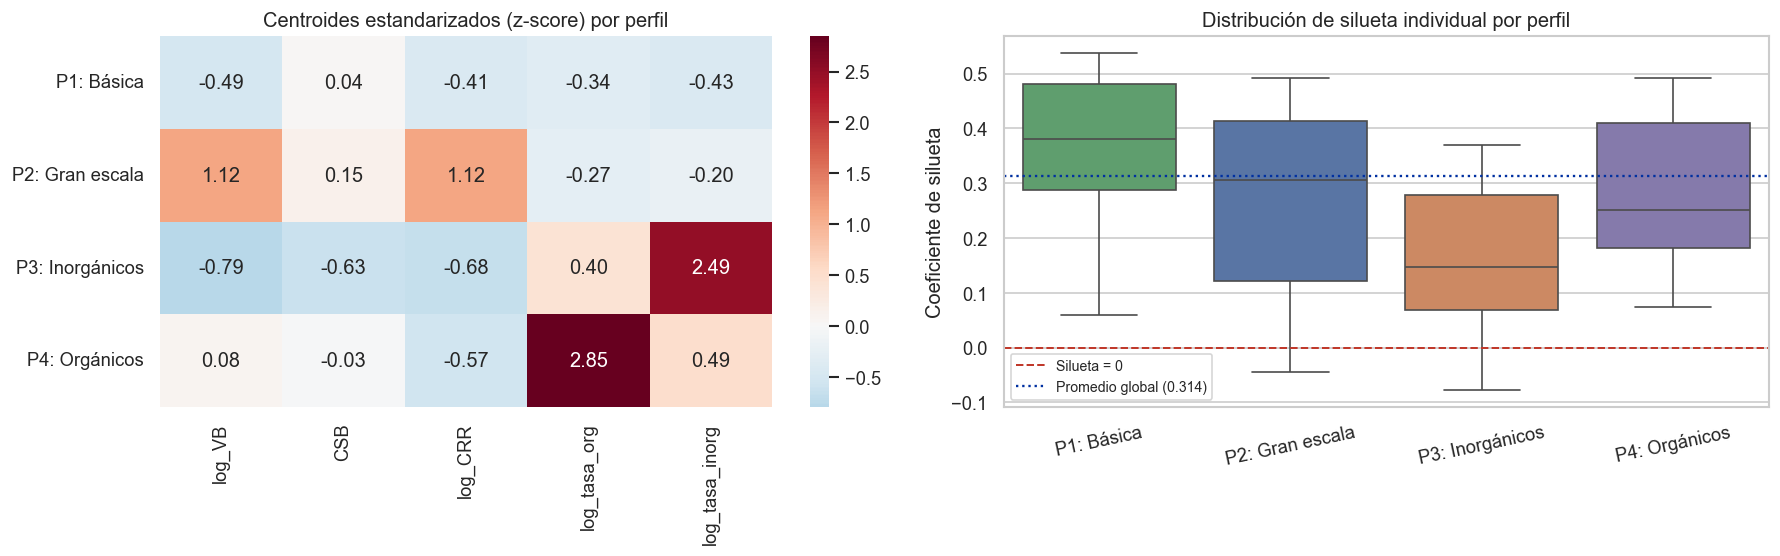

In [19]:
# Visualización de perfiles: Centroides estandarizados y distribución de silueta
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

cent_df = pd.DataFrame(X_B, columns=["log_VB", "CSB", "log_CRR", "log_tasa_org", "log_tasa_inorg"])
cent_df["Perfil"] = [short_names[c] for c in km4_lbl]
cent_means = cent_df.groupby("Perfil").mean().reindex([short_names[i] for i in range(4)])
sns.heatmap(cent_means, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("Centroides estandarizados (z-score) por perfil")
axes[0].set_ylabel("")

sns.boxplot(
    data=df_res, x="Perfil", y="silueta", hue="Perfil",
    order=[short_names[i] for i in range(4)],
    palette=[palette[i] for i in range(4)],
    legend=False, ax=axes[1]
)
axes[1].axhline(0, color="#c0392b", ls="--", lw=1.2, label="Silueta = 0")
axes[1].axhline(float(sil4.mean()), color="#0030A1", ls=":", lw=1.4, label=f"Promedio global ({sil4.mean():.3f})")
axes[1].set_title("Distribución de silueta individual por perfil")
axes[1].set_xlabel("")
axes[1].set_ylabel("Coeficiente de silueta")
axes[1].tick_params(axis="x", rotation=12)
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

### 6.1 Síntesis descriptiva de los 4 perfiles (sin orden jerárquico de calidad)
1. **P1 — Operación básica con alta cobertura de barrido (`n = 117`, 52.9%):** Cantones de escala pequeña a mediana (`CRR_t_mes` mediana = `270.0 t/mes`, `VB_km` = `12.54 km`) con cobertura de barrido completa (`CSB_limpia` = `1.00`), pero donde la valorización de residuos aún es incipiente (mediana `0%`; solo 14.5% trata orgánicos y 18.8% recupera inorgánicos). *Ejemplos típicos:* Espíndola, San Pedro de Huaca, Cevallos, Tisaleo.
2. **P2 — Operación urbana de gran escala centrada en recolección y barrido (`n = 65`, 29.4%):** Ciudades intermedias y grandes (`CRR_t_mes` mediana = `1,738.8 t/mes`, `VB_km` = `70.06 km`, `CSB_limpia` = `0.98`). Aunque 44.6% reporta alguna recuperación de inorgánicos y 27.7% algún tratamiento de orgánicos, sus **tasas relativas** frente al gran volumen recolectado siguen siendo bajas (medianas cercanas a `0%`). *Ejemplos típicos:* Salinas, Rumiñahui, Milagro, Quevedo (incluye también metrópolis como Quito, Guayaquil y Cuenca).
3. **P3 — Gestión con enfoque en recuperación de inorgánicos (`n = 22`, 10.0%):** Cantones pequeños y medianos (`CRR_t_mes` mediana = `120.0 t/mes`, `VB_km` = `9.00 km`) con cobertura de barrido moderada (`CSB_limpia` = `0.82`) donde el **100% recupera inorgánicos** en una proporción destacable (mediana `6.31%` de `CRR_t_mes`, equivalente a `8.45 t/mes`), y 59.1% también realiza algún tratamiento orgánico. *Ejemplos típicos:* Macará, San Lorenzo, Cuyabeno, Isabela.
4. **P4 — Gestión con valorización orgánica activa (`n = 17`, 7.7%):** Cantones pequeños y medianos (`CRR_t_mes` mediana = `135.0 t/mes`, `VB_km` = `23.50 km`, `CSB_limpia` = `1.00`) donde el **100% trata residuos orgánicos** con una tasa mediana de **`26.26%` de `CRR_t_mes`** (`32.00 t/mes`), y 76.5% además recupera inorgánicos. *Ejemplos típicos:* Pedro Vicente Maldonado, El Tambo, Biblián, Suscal.

### 6.2 Discusión de estabilidad, casos frontera y comparación de enfoques
- **¿Escala o prácticas de gestión?** En el **Enfoque A** (cantidades absolutas), la primera división responde principalmente al tamaño y la cobertura, con menor acuerdo entre K-Means y Ward (`ARI = 0.534` en $k=4$). Al incorporar tasas relativas válidas en el **Enfoque B**, los grupos reflejan simultáneamente **escala operativa** (P1 vs. P2) y **prácticas de valorización** (P3 inorgánicos, P4 orgánicos), elevando la concordancia K-Means vs. Ward a `0.831`.
- **¿Qué conclusiones permanecen estables?** Al variar $k$ (de 3 a 5), el algoritmo (K-Means vs. Ward) o la semilla (`n_init=20`), se mantienen constantes tres hallazgos estructurales: (i) más de la mitad de los cantones se concentra en recolección y barrido sin valorización significativa; (ii) las ciudades grandes conforman un bloque propio de alta escala con bajas tasas relativas de aprovechamiento; y (iii) existe un grupo compacto de cantones pequeños/medianos que lideran las tasas relativas de compostaje (17 cantones) o reciclaje inorgánico (21–22 cantones).
- **Cantones poco representados (casos frontera):** Solo 6 cantones presentan silueta negativa (como Nangaritza, San Jacinto de Yaguachi, Olmedo, Girón y Shushufindi), generalmente por combinar rasgos mixtos (p. ej., volumen alto con pocos km barridos en Yaguachi, o tasas moderadas de reciclaje con cobertura baja en Girón).

# 7. Conclusiones finales y propuestas técnicas (Hito 4)

### Respuesta a la pregunta esencial
En los registros GIRS 2024 del INEC emergen **cuatro perfiles diferenciados de gestión municipal** que combinan escala operativa y esfuerzo relativo de valorización: operación básica de escala pequeña/media (52.9%), operación urbana de gran escala centrada en recolección (29.4%), recuperación activa de inorgánicos (10.0%) y valorización orgánica activa (7.7%). Comunicar estos perfiles en **unidades originales** y sin numeración jerárquica evita estigmatizar a los municipios y permite focalizar el apoyo técnico según la realidad operativa de cada grupo.

### Propuestas de apoyo técnico vinculadas a cada perfil (e información adicional necesaria)
- **Para P1 (Operación básica, n=117):** explorar programas piloto de compostaje descentralizado o mancomunado (aprovechando escalas pequeñas) y diagnosticar barreras de separación en la fuente. *Información adicional requerida:* presupuesto municipal de aseo, existencia de rellenos/botaderos compartidos y estudios de caracterización de residuos (`PORG_ref_pct`, hoy faltante en más de la mitad de cantones).
- **Para P2 (Gran escala urbana, n=65):** evaluar cómo escalar el aprovechamiento de orgánicos e inorgánicos mediante convenios formales con asociaciones de recicladores de base y plantas de transferencia/compostaje, dado que pequeñas mejoras porcentuales impactan miles de toneladas mensuales. *Información adicional requerida:* cobertura real de recolección diferenciada, capacidad instalada de plantas y trazabilidad del reciclaje informal no captado por el GAD.
- **Para P3 (Enfoque en inorgánicos, n=22):** fortalecer la cobertura y registro del servicio de barrido (`CSB_limpia` mediana `0.82`), consolidar mercados locales para el material recuperado y explorar el aprovechamiento de la fracción orgánica. *Información adicional requerida:* costos logísticos de comercialización (especialmente en cantones amazónicos e insulares) y formalización de gestores.
- **Para P4 (Valorización orgánica activa, n=17):** documentar y sistematizar sus experiencias (como mancomunidades o plantas de compostaje locales) como casos de referencia transferibles a cantones de P1 con escala similar, verificando la calidad y demanda del abono producido. *Información adicional requerida:* sostenibilidad financiera de las plantas de compostaje y verificación de mediciones en báscula.

### Limitaciones principales y mejoras futuras
1. **Corte transversal único (2024):** no permite medir evolución temporal ni inferir causalidad; incorporar series multianuales del INEC permitiría evaluar transiciones entre perfiles.
2. **Calidad de autorreporte y unidades:** se detectaron inconsistencias puntuales en el denominador de `CSB` (4 cantones $>1$ y 4 nulos con servicio) y escala anual en `TROT`, lo que exige validar registros en campo antes de tomar decisiones presupuestarias.
3. **Subregistro del sector informal:** un valor de `0` en `RI_t_mes` indica ausencia de recuperación reportada por el municipio, no necesariamente ausencia de reciclaje informal en el territorio.

In [20]:
# === CELDA DE VERIFICACIÓN DE COHERENCIA (TEXTO VS. DATOS) ===
def verificar_coherencia_hito4(df, df_comp, df_res, var_ratio):
    print("=== AUDITORÍA AUTOMÁTICA DE COHERENCIA: DATOS vs. TEXTO ===\n")

    # 1. Dimensión y unicidad
    n_cantones = len(df)
    n_unicos = df["CantonId"].nunique()
    print(f"[1] Registros: {n_cantones} filas | CantonId únicos: {n_unicos} | Duplicados: {df.duplicated().sum()}")

    # 2. Disponibilidad y ceros en variables clave de la base limpia
    for col in ["VB_km", "CSB_limpia", "CRR_t_mes", "TROT_t_mes", "RI_t_mes", "Tasa_Org_pct", "Tasa_Inorg_pct", "PORG_ref_pct"]:
        if col in df.columns:
            s = pd.to_numeric(df[col], errors="coerce")
            nulos = int(s.isna().sum())
            ceros = int((s == 0).sum())
            print(f"    - {col:15s}: nulos={nulos} ({nulos/n_cantones*100:.2f}%), ceros={ceros} ({ceros/n_cantones*100:.2f}%), med={s.median():.2f}, max={s.max():.2f}")

    # 3. Métricas del modelo seleccionado (Enfoque B, k=4)
    fila_b4 = df_comp[(df_comp["Enfoque"].str.startswith("Enfoque B")) & (df_comp["k"] == 4)].iloc[0]
    print(f"\n[2] Enfoque B (k=4): Silueta KM={fila_b4['Silueta KM']}, Inercia={fila_b4['Inercia KM']}, "
          f"Tamaños KM={fila_b4['Tamaños KM']}, ARI(KM vs Ward)={fila_b4['ARI (KM vs Ward)']}")

    # 4. Tamaños y porcentajes por perfil
    conteos = df_res["cluster"].value_counts().sort_index()
    pcts = (conteos / n_cantones * 100).round(1)
    print(f"[3] Conteos por perfil (P1..P4): {conteos.tolist()} -> Porcentajes: {pcts.tolist()} (Suma={pcts.sum():.1f}%)")

    # 5. PCA varianza acumulada PC1+PC2
    pc12_pct = (var_ratio[0] + var_ratio[1]) * 100
    print(f"[4] PCA: PC1={var_ratio[0]*100:.2f}%, PC2={var_ratio[1]*100:.2f}%, PC1+PC2={pc12_pct:.2f}%")

    # 6. Casos frontera (silueta < 0)
    neg = df_res[df_res["silueta"] < 0].sort_values("silueta")
    print(f"[5] Silueta negativa (<0): {len(neg)} cantones -> {list(neg['NombreCantón'])}")

    # 7. Chequeo de valores máximos de tasas (deben estar <= 100% si TROT se ajustó a mes)
    max_org = df_res["tasa_org_pct"].max()
    max_inorg = df_res["tasa_inorg_pct"].max()
    print(f"[6] Tasas máximas: Org={max_org:.2f}%, Inorg={max_inorg:.2f}% "
          f"({'OK (<=100%)' if max_org <= 100 and max_inorg <= 100 else 'REVISAR UNIDADES (>100%)'})")

verificar_coherencia_hito4(df, df_comp, df_res, var_ratio)

=== AUDITORÍA AUTOMÁTICA DE COHERENCIA: DATOS vs. TEXTO ===

[1] Registros: 221 filas | CantonId únicos: 221 | Duplicados: 0
    - VB_km          : nulos=0 (0.00%), ceros=2 (0.90%), med=18.11, max=4840.00
    - CSB_limpia     : nulos=0 (0.00%), ceros=2 (0.90%), med=1.00, max=1.00
    - CRR_t_mes      : nulos=0 (0.00%), ceros=0 (0.00%), med=369.30, max=121905.60
    - TROT_t_mes     : nulos=0 (0.00%), ceros=156 (70.59%), med=0.00, max=828.32
    - RI_t_mes       : nulos=0 (0.00%), ceros=135 (61.09%), med=0.00, max=1420.07
    - Tasa_Org_pct   : nulos=0 (0.00%), ceros=156 (70.59%), med=0.00, max=61.80
    - Tasa_Inorg_pct : nulos=0 (0.00%), ceros=139 (62.90%), med=0.00, max=36.61
    - PORG_ref_pct   : nulos=113 (51.13%), ceros=2 (0.90%), med=58.95, max=86.43

[2] Enfoque B (k=4): Silueta KM=0.314, Inercia=528.9, Tamaños KM=[117, 65, 22, 17], ARI(KM vs Ward)=0.831
[3] Conteos por perfil (P1..P4): [117, 65, 22, 17] -> Porcentajes: [52.9, 29.4, 10.0, 7.7] (Suma=100.0%)
[4] PCA: PC1=38.95%,